# Credit Risk Scorecard

Saya meninjau artefak hasil eksekusi pipeline. Notebook ini memverifikasi hash sumber tabel/grafik dan menghitung ulang metrik penting tanpa melatih ulang pada data uji.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image
root = Path.cwd()
manifest = json.loads(Path('reports/artifact_manifest.json').read_text())
for file, expected in manifest.items():
    assert hashlib.sha256(Path(file).read_bytes()).hexdigest() == expected, file
result = json.loads(Path('reports/hasil.json').read_text())
display(result)


{'seed': 2024,
 'n': 1000,
 'train_n': 800,
 'test_n': 200,
 'bad_n': 300,
 'missing_cells': 0,
 'exact_duplicate_rows': 0,
 'selected_attributes': ['checking',
  'duration',
  'history',
  'purpose',
  'amount',
  'savings',
  'employment',
  'personal_status_sex',
  'debtors',
  'property',
  'age',
  'other_plans',
  'housing'],
 'oof_choice': {'cutoff': 0.16466980380739774,
  'cost': 400.0,
  'wrong_approve': 27.0,
  'wrong_reject': 265.0,
  'tn': 295.0,
  'fp': 265.0,
  'fn': 27.0,
  'tp': 213.0,
  'approval_rate': 0.4025},
 'scorecard': {'auc': 0.7655952380952381,
  'gini': 0.5311904761904762,
  'ks': 0.4714285714285714,
  'brier': 0.17475152295679702},
 'boosting': {'auc': 0.7772619047619048,
  'gini': 0.5545238095238096,
  'ks': 0.46190476190476193,
  'brier': 0.16950698437861458},
 'oof_scorecard': {'auc': 0.7749776785714285,
  'gini': 0.549955357142857,
  'ks': 0.41845238095238096,
  'brier': 0.17268350875809646},
 'oof_boosting': {'auc': 0.7628273809523811,
  'gini': 0.52565

## Kualitas dan ringkasan data

Saya memeriksa ukuran dan distribusi atribut sebelum menafsirkan model.

In [2]:
table = pd.read_csv('reports/eda.csv')
display(table)

,Unnamed: 0,checking,duration,history,purpose,amount,savings,employment,installment,personal_status_sex,...,property,age,other_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,label
0,count,1000,1000.000000,1000,1000,1000.000000,1000,1000,1000.000000,1000,...,1000,1000.000000,1000,1000,1000.000000,1000,1000.000000,1000,1000,1000.000000
1,unique,4,NaN,5,10,NaN,5,5,NaN,4,...,4,NaN,3,3,NaN,4,NaN,2,2,NaN
2,top,A14,NaN,A32,A43,NaN,A61,A73,NaN,A93,...,A123,NaN,A143,A152,NaN,A173,NaN,A191,A201,NaN
3,freq,394,NaN,530,280,NaN,603,339,NaN,548,...,332,NaN,814,713,NaN,630,NaN,596,963,NaN
4,mean,NaN,20.903000,NaN,NaN,3271.258000,NaN,NaN,2.973000,NaN,...,NaN,35.546000,NaN,NaN,1.407000,NaN,1.155000,NaN,NaN,1.300000
5,std,NaN,12.058814,NaN,NaN,2822.736876,NaN,NaN,1.118715,NaN,...,NaN,11.375469,NaN,NaN,0.577654,NaN,0.362086,NaN,NaN,0.458487
6,min,NaN,4.000000,NaN,NaN,250.000000,NaN,NaN,1.000000,NaN,...,NaN,19.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,1.000000
7,25%,NaN,12.000000,NaN,NaN,1365.500000,NaN,NaN,2.000000,NaN,...,NaN,27.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,1.000000
8,50%,NaN,18.000000,NaN,NaN,2319.500000,NaN,NaN,3.000000,NaN,...,NaN,33.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,1.000000
9,75%,NaN,24.000000,NaN,NaN,3972.250000,NaN,NaN,4.000000,NaN,...,NaN,42.000000,NaN,NaN,2.000000,NaN,1.000000,NaN,NaN,2.000000


## IV pada data latih

Saya memilih atribut dari IV latih saja; setiap fold menghitung ulang bin, WoE, dan IV.

In [3]:
table = pd.read_csv('reports/information_value.csv')
display(table)

,attribute,iv,selected
0,checking,0.602257,True
1,history,0.284611,True
2,purpose,0.191645,True
3,savings,0.190332,True
4,duration,0.160005,True
5,amount,0.146464,True
6,age,0.119345,True
7,employment,0.101306,True
8,personal_status_sex,0.092559,True
9,property,0.081180,True


## Koefisien logistik

Saya menafsirkan koefisien dengan target bad=1. P-value pascaseleksi bersifat eksploratif.

In [4]:
table = pd.read_csv('reports/coefficients.csv')
display(table)

,attribute,coefficient,p_value,ci_low,ci_high
0,const,-0.860573,6.169542e-20,-1.045086,-0.676060
1,checking,-0.826219,2.599484e-11,-1.069087,-0.583350
2,duration,-0.853011,4.541969e-04,-1.329815,-0.376207
3,history,-0.645957,3.788270e-04,-1.002149,-0.289765
4,purpose,-1.000828,4.479934e-06,-1.428396,-0.573260
5,amount,-0.942388,1.380802e-04,-1.426976,-0.457800
6,savings,-0.812413,3.623861e-04,-1.258928,-0.365898
7,employment,-0.626018,3.595207e-02,-1.210996,-0.041040
8,personal_status_sex,-0.934184,2.892112e-03,-1.548813,-0.319555
9,debtors,-1.327470,1.368090e-02,-2.382735,-0.272205


## Evaluasi uji

Saya menghitung metrik pada 200 baris uji sesudah membekukan model dan cutoff.

In [5]:
table = pd.read_csv('reports/evaluation.csv')
display(table)

,model,auc,gini,ks,brier
0,scorecard,0.765595,0.531190,0.471429,0.174752
1,boosting,0.777262,0.554524,0.461905,0.169507


## Cutoff dan biaya

Saya memilih cutoff memakai OOF latih; tabel uji berikut hanya sensitivitas.

In [6]:
table = pd.read_csv('reports/cutoffs.csv')
display(table)

,cutoff,cost,wrong_approve,wrong_reject,tn,fp,fn,tp,approval_rate
0,0.10000,121,5,96,44,96,5,55,0.245
1,0.16467,114,8,74,66,74,8,52,0.370
2,0.20000,107,9,62,78,62,9,51,0.435
3,0.30000,114,14,44,96,44,14,46,0.550
4,0.50000,149,25,24,116,24,25,35,0.705


## Audit kelompok

Saya melaporkan ukuran kelompok dan interval approval, tanpa menyimpulkan kepatuhan.

In [7]:
table = pd.read_csv('reports/fairness.csv')
display(table)

,attribute,group,n,bad_n,approval_rate,approval_ci_low,approval_ci_high,false_reject_rate_good,false_approve_rate_bad,brier
0,age,25-49,145,43,0.379310,0.304411,0.460440,0.509804,0.116279,0.156729
1,age,50+,23,7,0.478261,0.292369,0.670376,0.437500,0.285714,0.195204
2,age,<25,32,10,0.250000,0.132522,0.421069,0.681818,0.100000,0.241716
3,sex,female,64,15,0.296875,0.199050,0.417704,0.612245,0.000000,0.147147
4,sex,male,136,45,0.404412,0.325652,0.488424,0.483516,0.177778,0.187742


## Pemeriksaan konsistensi

Saya menghitung ulang hubungan pokok dari prediksi tersimpan.

In [8]:
from sklearn.metrics import roc_auc_score, brier_score_loss
from src.scorecard import score_to_probability, decision_cost
pred = pd.read_csv('reports/test_predictions.csv')
assert np.allclose(score_to_probability(pred.score), pred.probability)
assert np.isclose(roc_auc_score(pred.default, pred.probability), result['scorecard']['auc'])
assert np.isclose(brier_score_loss(pred.default, pred.probability), result['scorecard']['brier'])
assert decision_cost(pred.default, pred.probability, result['test_decision']['cutoff'])['cost'] == result['test_decision']['cost']
print('Skor, probabilitas, AUC, Brier, dan biaya konsisten.')

Skor, probabilitas, AUC, Brier, dan biaya konsisten.


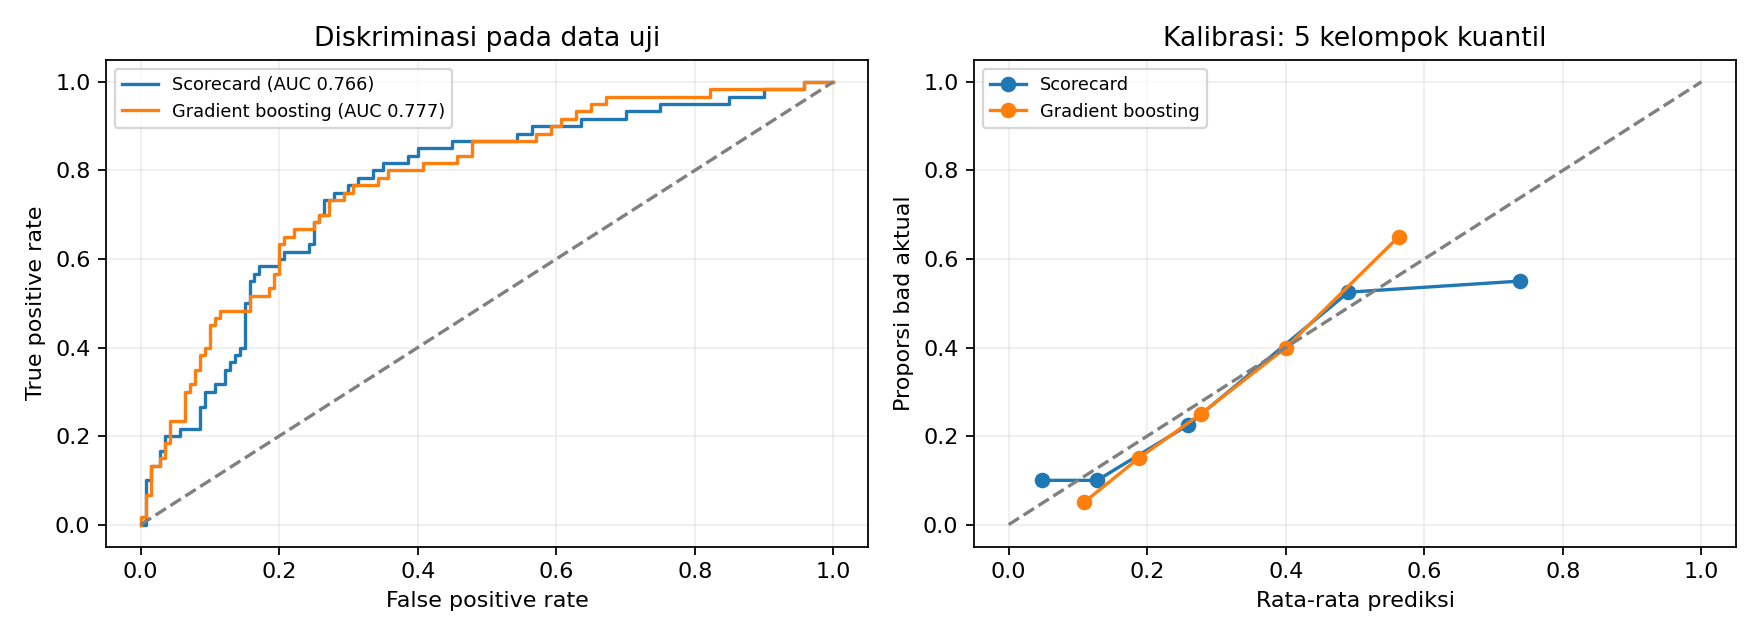

In [9]:
display(Image(filename='assets/evaluation.png'))

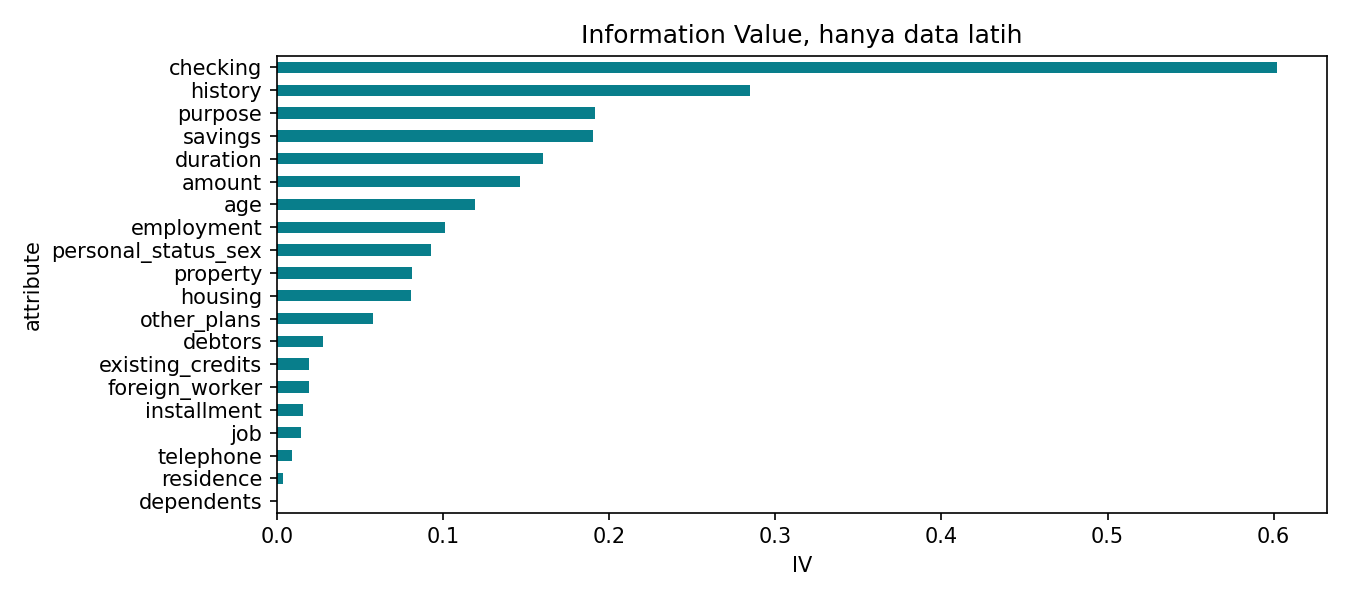

In [10]:
display(Image(filename='assets/information_value.png'))

## Interpretasi dan batas penggunaan

Saya membaca hasil sebagai studi portofolio. Penjelasan lengkap, audit data, keputusan berbasis latih, dan keterbatasan tersedia di reports/laporan_analisis.md.